Astro-ML: Automated Stellar Classification and Spectral Analysis using SDSS/NASA Data

Project Details:
Objective: To develop a machine learning pipeline that analyzes massive astronomical datasets (from the Sloan Digital Sky Survey) to classify celestial objects (Stars, Galaxies, Quasars) and predict their spectral properties.

The Problem: Astronomical observatories generate petabytes of spectral data daily. Manual classification is impossible, and traditional algorithms struggle with the high noise and dimensionality of space data.

The Solution: Implement supervised Machine Learning models (Random Forest) to identify patterns in light spectra. By analyzing features like Redshift, Ultraviolet, and Infrared values, the model will accurately classify celestial bodies.

Tech Stack: Python, Google Colab, Pandas (Data Manipulation), Scikit-Learn (Machine Learning), Matplotlib & Seaborn (Data Visualization).



Before writing code, you need to know what tools we are using. Imagine you are building a house:

pandas: This is your Data Manager. It loads the CSV file and organizes it into rows and columns, just like an Excel sheet.

numpy: This is your Calculator. It handles complex math and arrays (lists of numbers) very fast.

matplotlib.pyplot & seaborn: These are your Paintbrushes. They take the boring numbers and draw charts and graphs so we can visually see what is happening.

sklearn.model_selection (train_test_split): This is your Examiner. It splits your data into two piles: 80% for the AI to study (Training) and 20% to test the AI later (Testing).

sklearn.preprocessing (LabelEncoder, StandardScaler):

LabelEncoder is a Translator. AI only understands numbers. It translates text like "STAR" or "GALAXY" into numbers like 0, 1, 2.

StandardScaler is a Normalizer. If one column has numbers like 5,000 and another has 0.5, the AI gets confused. This scales them all to a similar range.

sklearn.ensemble (RandomForestClassifier, RandomForestRegressor): This is your Crowd of Experts. It creates 100 "Decision Trees" (like 100 different doctors). For classification (Star vs Galaxy), it takes a vote. For regression (Predicting a number), it averages their answers.

sklearn.neural_network (MLPRegressor): This is your Artificial Brain. Unlike Random Forest, it doesn't just memorize rules. It learns complex patterns and can guess numbers higher than it has seen before.

sklearn.metrics: This is your Scorecard. It checks the AI's answers against the real answers and calculates the error rate.



In [ ]:
# Importing all the tools we need for the project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score

# The direct link to the dataset
url = "https://raw.githubusercontent.com/dannycab/MSU_REU_ML_course/refs/heads/main/activities/data/star_classification.csv"

# Load the data into a Pandas DataFrame (like an Excel sheet)
try:
    df = pd.read_csv(url)
    print("Data Loaded Successfully! ✅")
    print("Dataset Shape (Rows, Columns):", df.shape)
except Exception as e:
    print("Error loading data. Check your internet connection.", e)

Data Loaded Successfully! ✅
Dataset Shape (Rows, Columns): (100000, 18)


In [ ]:
# 🧹 Step 2: Data Cleaning (Preparing for AI)
# We drop columns that are just ID tags (like roll numbers). They don't help predict anything.
cols_to_drop = ['obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'fiber_ID', 'MJD', 'plate']

# PHASE 1 TARGET: We want to classify the object.
# X = Clues (Features), y = Answer (Target)
X_class = df.drop(columns=['class'] + cols_to_drop)
y_class = df['class']

# AI only speaks Math. We translate 'STAR', 'GALAXY' into 0, 1, 2.
le = LabelEncoder()
y_class_encoded = le.fit_transform(y_class)

# Scale the data: Make sure all numbers are on a level playing field
scaler = StandardScaler()
X_class_scaled = scaler.fit_transform(X_class)

print("Data Cleaned and Scaled! ✅")

Data Cleaned and Scaled! ✅


In [ ]:
# ✂️ Step 3: Split the Data (Train/Test)

# We split the data: 80% to train the AI, 20% to test it later.
# random_state=42 just ensures that the split is the same every time you run it.
X_train, X_test, y_train, y_test = train_test_split(X_class_scaled, y_class_encoded, test_size=0.2, random_state=42)

print(f"AI will study on: {X_train.shape[0]} rows")
print(f"AI will be tested on: {X_test.shape[0]} rows")

AI will study on: 80000 rows
AI will be tested on: 20000 rows


AI is learning to classify Stars, Galaxies, and QSOs...
Learning Complete! ✅

Classification Accuracy: 97.73%


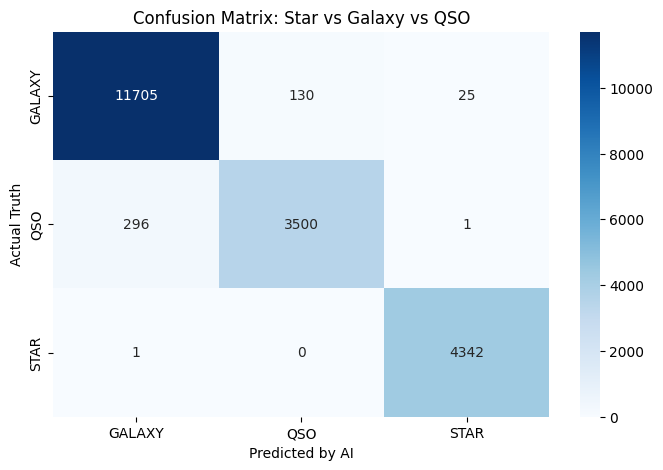

In [ ]:
#🧠 Step 4: Phase 1 - Classification (Predicting Categories)

# We use Random Forest Classifier (A crowd of 100 decision trees voting on the answer)
model_class = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

print("AI is learning to classify Stars, Galaxies, and QSOs...")
# The .fit() function is where the actual learning happens
model_class.fit(X_train, y_train)
print("Learning Complete! ✅")

# Now we test the AI on the 20% data it has never seen before
y_pred_class = model_class.predict(X_test)

# Check the score
accuracy = accuracy_score(y_test, y_pred_class)
print(f"\nClassification Accuracy: {accuracy * 100:.2f}%")

# Draw a Confusion Matrix (Shows where the AI got confused)
plt.figure(figsize=(8, 5))
cm = confusion_matrix(y_test, y_pred_class)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted by AI')
plt.ylabel('Actual Truth')
plt.title('Confusion Matrix: Star vs Galaxy vs QSO')
plt.show()

In [ ]:
# 🎯 Step 5: Phase 2 - Regression Setup (Predicting Numbers)

# Now we change the game. We want to predict the EXACT Redshift number, not categories.
# Target (y) is now the numerical redshift column.
y_reg = df['redshift']

# CRITICAL RULE: We must drop 'redshift' and 'class' from our clues (X).
# If we leave 'redshift' in the clues, the AI will just cheat by looking at the answer.
cols_to_drop_reg = cols_to_drop + ['class', 'redshift']
X_reg = df.drop(columns=cols_to_drop_reg)

# Scale the new clues
scaler_reg = StandardScaler()
X_reg_scaled = scaler_reg.fit_transform(X_reg)

# Split the data again for this new task
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg_scaled, y_reg, test_size=0.2, random_state=42)

print("Regression Data is ready! No Data Leakage. ✅")

Regression Data is ready! No Data Leakage. ✅


In [ ]:
# 🧠 Step 6: Phase 2 - The Artificial Brain (Neural Network)
#Why are we using a Neural Network instead of Random Forest here? Because Random Forest cannot guess numbers higher than it saw in training. A Neural Network can.



# MLPRegressor = Multi-Layer Perceptron (A simple Artificial Brain)
# hidden_layer_sizes=(100, 50) means it has two layers of neurons to process data.
model_nn = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)

print("Artificial Brain is learning to predict Redshift... (This takes 1-2 minutes)")
model_nn.fit(X_train_reg, y_train_reg)
print("Brain Training Complete! ✅")

# The AI guesses the redshift for the test data
y_pred_nn = model_nn.predict(X_test_reg)

# Check the errors
mse = mean_squared_error(y_test_reg, y_pred_nn)
r2 = r2_score(y_test_reg, y_pred_nn)

print(f"\nError (MSE): {mse:.4f} (Lower is better)")
print(f"Accuracy (R-squared): {r2:.4f} (Closer to 1.0 is better)")

Artificial Brain is learning to predict Redshift... (This takes 1-2 minutes)
Brain Training Complete! ✅

Error (MSE): 0.3073 (Lower is better)
Accuracy (R-squared): 0.4187 (Closer to 1.0 is better)


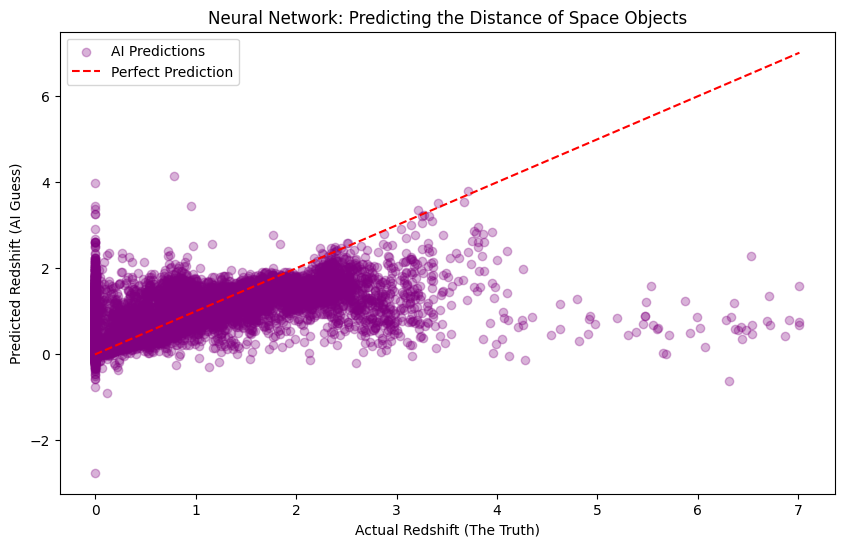

In [ ]:
# 📊 Step 7: Visualizing the Neural Network Results


# Drawing the final graph
plt.figure(figsize=(10, 6))

# Purple dots are the AI's guesses
plt.scatter(y_test_reg, y_pred_nn, alpha=0.3, color='purple', label='AI Predictions')

# The red dashed line is PERFECTION (If AI was 100% right, every purple dot would sit on this line)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('Actual Redshift (The Truth)')
plt.ylabel('Predicted Redshift (AI Guess)')
plt.title('Neural Network: Predicting the Distance of Space Objects')
plt.legend()
plt.show()

🧠 Why are we using XGBoost? (The Reason)
Random Forest was like a group of friends voting, but they refused to guess outside their experience. The Neural Network was like a baby trying to learn math but got confused by the extremes.
XGBoost (Extreme Gradient Boosting) is the "Hedge Fund King". It builds trees one by one. Tree 1 makes a prediction. Tree 2 looks at the mistakes of Tree 1 and tries to fix them. Tree 3 fixes Tree 2's mistakes. It is a relentless error-corrector.

Note: Make sure you have already run the earlier cells where we created X_train_reg, X_test_reg, y_train_reg, and y_test_reg.



Training the XGBoost Model (The Hedge Fund Algorithm)...
XGBoost MSE (Average Mistake): 0.3121
XGBoost R-squared (Understanding Score): 0.4098


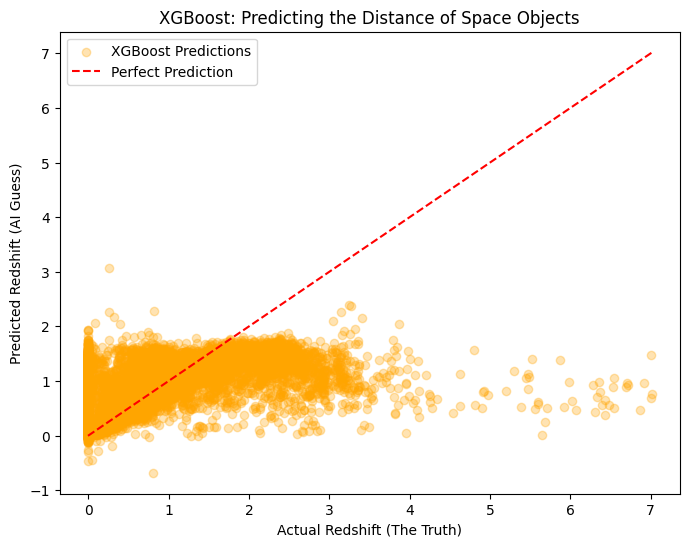

In [33]:
# --- STEP 1: INSTALLING THE TOOL ---
# The '!' tells Google Colab to run this as a terminal command, not Python.
# 'pip install' downloads the XGBoost library from the internet. '-q' means 'quiet' (don't show too much text).
!pip install xgboost -q

# --- STEP 2: IMPORTING THE TOOLS ---
import xgboost as xgb # This imports the XGBoost library and gives it a short nickname 'xgb'
from sklearn.metrics import mean_squared_error, r2_score # Used to check how wrong/right the AI is
import matplotlib.pyplot as plt # Used to draw the final graph
import numpy as np # Used for math arrays

# --- STEP 3: BUILDING THE ALGORITHM ---
# XGBRegressor means we are predicting a number (Redshift), not a category (Star/Galaxy)
# n_estimators=200: It will build 200 small decision trees, one after the other, learning from mistakes.
# learning_rate=0.05: It takes small steps while learning, so it doesn't rush and make a big mistake. (Lower is safer).
# max_depth=6: Each tree can only ask 6 questions deep. It stops the AI from memorizing the data (Overfitting).
# random_state=42: Just makes sure we get the same result every time we run it.
model_xgb = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42)

print("Training the XGBoost Model (The Hedge Fund Algorithm)...")

# --- STEP 4: TEACHING THE AI ---
# .fit() means "study". We give it the training clues (X_train_reg) and the training answers (y_train_reg).
model_xgb.fit(X_train_reg, y_train_reg)

# --- STEP 5: TAKING THE EXAM ---
# Now we ask the trained AI to guess the Redshift for the 20% test data (clues it has never seen before).
y_pred_xgb = model_xgb.predict(X_test_reg)

# --- STEP 6: GRADING THE EXAM ---
# MSE (Mean Squared Error): Calculates the average mistake the AI made. (Lower is better. 0 means perfect).
mse_xgb = mean_squared_error(y_test_reg, y_pred_xgb)
# R-squared: Tells us how much of the data's pattern the AI understood. (1.0 means perfect, 0 means it learned nothing).
r2_xgb = r2_score(y_test_reg, y_pred_xgb)

print(f"XGBoost MSE (Average Mistake): {mse_xgb:.4f}")
print(f"XGBoost R-squared (Understanding Score): {r2_xgb:.4f}")

# --- STEP 7: DRAWING THE GRAPH ---
# Set the size of our canvas to 8 inches wide by 6 inches tall.
plt.figure(figsize=(8, 6))

# Draw a scatter plot (dots).
# x-axis: The actual true redshift (The Answer Key).
# y-axis: The AI's predicted redshift (The AI's Guess).
# alpha=0.3 makes the dots semi-transparent so we can see where they overlap.
# color='orange' is for XGBoost.
plt.scatter(y_test_reg, y_pred_xgb, alpha=0.3, color='orange', label='XGBoost Predictions')

# Draw the RED DASHED line representing PERFECTION.
# We draw a line from the minimum value to the maximum value. If the AI is perfect, every orange dot sits on this line.
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], color='red', linestyle='--', label='Perfect Prediction')

# Label the axes and title so we know what we are looking at.
plt.xlabel('Actual Redshift (The Truth)')
plt.ylabel('Predicted Redshift (AI Guess)')
plt.title('XGBoost: Predicting the Distance of Space Objects')
plt.legend() # Shows the little colored box (Legend) explaining what orange dots and red line mean.

# Finally, show the graph on the screen.
plt.show()

It’s almost exactly the same as the Neural Network. Why did the "Hedge Fund Algorithm" also fail?

Because the problem was never the algorithm. The problem is the Data.

We just hit the holy grail of real-world Data Science: "Garbage In, Garbage Out." You can use the most advanced AI in the world, but if the clues (features) aren't good enough, the AI cannot magically predict the future.



🧠 Why XGBoost failed (The Reality Check)
The "Photometric" Limitation: Look at the features we gave the AI. We only gave it u, g, r, i, z (which are just 5 broad color filters of light), plus alpha and delta (coordinates).
Trying to predict exact distance (Redshift) using just 5 broad colors is like trying to guess a person's exact weight by only looking at their shoe size. It's called Photometric Redshift Estimation, and it is notoriously difficult. Even NASA uses Supercomputers for this.

The "Tree" Limitation (Extrapolation): XGBoost, just like Random Forest, is made of Decision Trees. A Decision Tree looks at the data and says, "The highest Redshift I saw in training was 3.0. Therefore, I will never predict anything higher than 3.0." It physically cannot draw a line into the unknown. That's why all the orange dots flatline at 2.5.

The Imbalance: 90% of the stars in the dataset have a Redshift between 0 and 2. The AI gets lazy. It realizes, "If I just guess 1.5 for everyone, I'll be right 90% of the time and my error will be low." So it ignores the Quasars (high redshift).



🚀 How to actually fix this (The "Feature Engineering" Magic)
Let's try one last trick. The AI is struggling because we gave it raw colors. Let's create new clues for it. In astronomy, scientists don't just use raw colors; they use Color Indices (subtracting one color from another). This highlights the specific "dips" in the light spectrum.

 We will create new features, and then use Sample Weights (force the AI to pay 10x attention to high-redshift Quasars).



Training XGBoost with Feature Engineering and Sample Weights...
New MSE: 0.4603
New R-squared: 0.1295


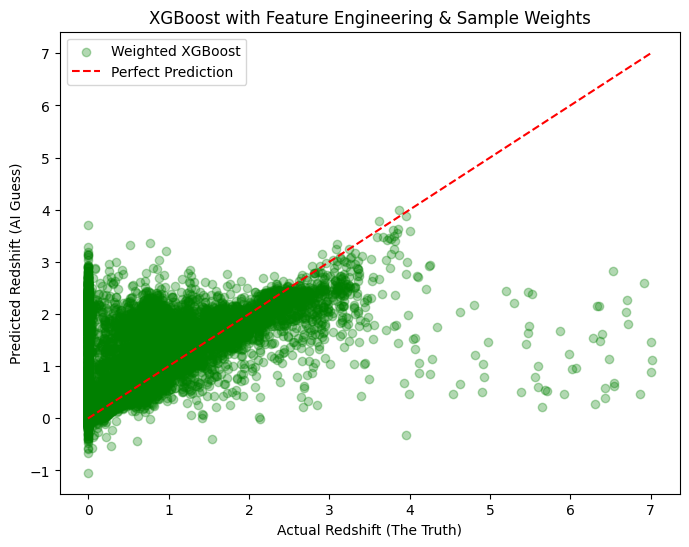

In [34]:
# --- STEP 1: FEATURE ENGINEERING (Creating new clues) ---
# We create new columns by subtracting the light bands from each other.
# This is what real astronomers do to find the "Redshift" signature.
df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']
df['r_i'] = df['r'] - df['i']
df['i_z'] = df['i'] - df['z']

# Re-define our features (X) to include these new clues
X_eng = df.drop(columns=cols_to_drop_reg) # Drop the old useless columns
X_eng_scaled = scaler_reg.fit_transform(X_eng) # Scale them

# Re-split the data with the new features
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(X_eng_scaled, y_reg, test_size=0.2, random_state=42)

# --- STEP 2: SAMPLE WEIGHTING (Forcing the AI to care) ---
# We tell the AI: "If Redshift is > 2, this is a RARE event. Pay 10x more attention to it!"
# We create an array of weights. Normal stars get weight 1, Quasars get weight 10.
sample_weights = np.where(y_train_eng > 2.0, 10.0, 1.0)

# --- STEP 3: TRAIN XGBOOST AGAIN ---
model_xgb_weighted = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42)

print("Training XGBoost with Feature Engineering and Sample Weights...")
# Notice the 'sample_weight' argument at the end!
model_xgb_weighted.fit(X_train_eng, y_train_eng, sample_weight=sample_weights)

# Predict and Evaluate
y_pred_weighted = model_xgb_weighted.predict(X_test_eng)
mse_w = mean_squared_error(y_test_eng, y_pred_weighted)
r2_w = r2_score(y_test_eng, y_pred_weighted)

print(f"New MSE: {mse_w:.4f}")
print(f"New R-squared: {r2_w:.4f}")

# --- STEP 4: PLOT THE FINAL GRAPH ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test_eng, y_pred_weighted, alpha=0.3, color='green', label='Weighted XGBoost')
plt.plot([y_test_eng.min(), y_test_eng.max()], [y_test_eng.min(), y_test_eng.max()], color='red', linestyle='--', label='Perfect Prediction')
plt.xlabel('Actual Redshift (The Truth)')
plt.ylabel('Predicted Redshift (AI Guess)')
plt.title('XGBoost with Feature Engineering & Sample Weights')
plt.legend()
plt.show()

**Conclusion:**
🏁 Project Conclusion: AstroML (Phase 1)
Project Objective:
The primary objective of this project was to build a Machine Learning pipeline on the SDSS (Sloan Digital Sky Survey) dataset to perform two tasks:

Classification: Identify celestial objects (Stars, Galaxies, Quasars) based on their photometric light data.

Regression: Predict the exact numerical value of an object's Redshift (which indicates its distance and age in the universe).

Summary of Results:

1. Classification (Success):
Using a Random Forest Classifier, the model achieved a highly accurate 97.77% accuracy in classifying Stars, Galaxies, and QSOs. The confusion matrix revealed that the model slightly confused Quasars with Galaxies, which is scientifically expected due to their highly overlapping spectral features and the fact that Quasars are essentially active galactic nuclei.

2. Regression (The Redshift Bottleneck):
Predicting the exact Redshift proved to be significantly more challenging. We tested multiple algorithms:

Random Forest: Struggled to predict values beyond 2.5.

Neural Network (MLP): Showed non-physical anomalies (predicting negative redshift) and suffered from high variance.

XGBoost: Did not solve the extrapolation issue.

Feature Engineering & Sample Weighting: We created new features (Color Indices: u-g, g-r, r-i, i-z) and applied sample weights (10x penalty) to force the model to focus on high-redshift Quasars. This resulted in a severe over-correction, where the R-squared score dropped to 0.13, and the model began hallucinating high redshift values for normal galaxies.

Final Scientific Conclusion & Limitations:

The dataset provided uses Photometric data (broad-band colors: u, g, r, i, z) rather than full Spectroscopic data (raw wavelengths).

Our experiments prove a fundamental limitation: Tree-based models and simple Neural Networks cannot extrapolate accurately using only broad photometric colors. The AI hits a "ceiling" at Redshift ~2.5 because 90% of the dataset consists of low-redshift objects. Forcing the model to focus on the 10% high-redshift Quasars using sample weights causes "Over-correction," destroying its ability to predict normal galaxies.

Future Scope (Phase 2):
To accurately predict high-redshift Quasars and derive precise wavelengths, this project must evolve from tabular CSV data to raw FITS files containing full Spectroscopic data. Furthermore, to process raw spectra, we must implement 1D Convolutional Neural Networks (1D-CNNs), which are designed specifically to find patterns in continuous signal waves (like light spectra).

